# Stage 2: Geospatial Basics & Coastal Exposure Data
- GeoDataFrames, Points and Polygons
- Plotting (matplotlib) and Interactive Maps (folium)
- Real Boundary Data (Natural Earth) and Spatial Checks (`.within()`)
- Coordinate Reference Systems and Buffers (EPSG:4326 vs EPSG:3577)
- Reproducibility and Sampling (random seeds, hit rates)

## Task
Using the exposure data from Stage 1, add spatial awareness and rebuild the dataset so the properties sit in a realistic coastal zone. Steps to work through:
- Convert `latitude`/`longitude` into a `geometry` column with `gpd.points_from_xy()` and label it as lat/long (`EPSG:4326`)
- Load the Queensland boundary from Natural Earth's Admin 1 states/provinces dataset, and plot the points over it
- Use `.within()` to check which points fall inside Queensland (7 of 10 did, because a rectangular bounding box is not the coastline)
- Reproject to a metre-based CRS (`EPSG:3577`) so a buffer distance is a true distance, not degrees
- Build a 50 km coastal zone: shrink the all-Australia shape inward by 50 km, subtract that interior, and intersect the remaining strip with Queensland (using all of Australia means state land borders are not treated as coast)
- Sample random points in the coastal zone's bounding box and keep those inside it, then compare the sampled hit rate with the exact area ratio as a sanity check (0.057 vs 0.0603)
- Rebuild the exposure table (`policy_id`, `latitude`, `longitude`, `construction_type`, `sum_insured`), validate that all 10 points are inside Queensland and the coastal zone, and save to `exposure_data_coastal.csv`
- Build a final interactive `folium` map with the boundary, coastal zone, colour-coded properties, a legend and a layer toggle

*Rule of thumb: do geometry in metres, display in whichever CRS reads best.*

*For an alternative approach guaranteeing exactly 10 valid points via rejection sampling, see `02a_qld_boundary_resampling.ipynb`.*

*Next: join the properties to the AS/NZS 1170.2 wind regions (hazard layer).*

In [134]:
# load packages
import geopandas as gpd
import pandas as pd
import folium
import numpy as np

In [135]:
# your df should already exist from Stage 1, or re-load it from the CSV
df = pd.read_csv("exposure_data.csv")

In [136]:
# creating a geo-dataframe that stores lat and long in a POINT(long, lat) structure i.e. POINT(x, y)
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"])
)

gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552)
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143)
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607)
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161)
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778)
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807)
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303)
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589)
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662)
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313)


In [137]:
# and initial check of the points on a graph
#gdf.plot()

In [138]:
# adding a map for context

# create the base map
m = folium.Map(location=[-20, 147], zoom_start=5)

# loop through each row and add a marker
for idx, row in gdf.iterrows():
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=f"Policy {row['policy_id']}"  # try adding more info here if you want
    ).add_to(m)
m.save("test_map.html")
m


(Added this markdown cell to make the folio map appear: https://github.com/microsoft/vscode-jupyter/issues/17224#issuecomment-3724749068)

In [139]:
# The points we plotted are randomly generated which is why some are out in the open ocean. 
# Instead, we can load a real QLD coastline to constrain our points.

## Natural Earth Boundaries

In [140]:
# download from website and check for name of states
world_states = gpd.read_file("https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip")
world_states.columns

Index(['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2',
       'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt',
       ...
       'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT', 'FCLASS_NL',
       'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'FCLASS_TLC', 'geometry'],
      dtype='str', length=122)

In [141]:
# check Queensland is an option to filter for
qld = world_states[world_states["name"] == "Queensland"]
qld


,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


In [142]:
# check Queensland is in Australia (i.e. there's no other QLDs in the world)

qld = world_states[(world_states["name"] == "Queensland") & (world_states["iso_a2"] == "AU")]
qld

,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


## Comparing points and boundaries

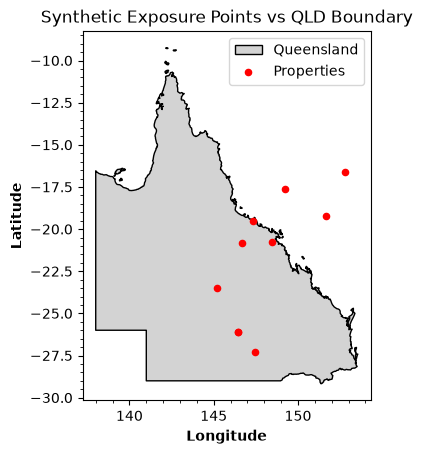

In [143]:
# plotting the QLD polygon and our randomly generated points.
# note that the geometry is a multipolygon as QLD also includes the islands 
# such as the Whitsundays which aren't connected to the mainland.

ax = qld.plot(color="lightgrey", edgecolor="black", label="Queensland")
gdf.plot(ax=ax, color="red", markersize=20, label="Properties")

ax.set_title("Synthetic Exposure Points vs QLD Boundary")
ax.set_xlabel("Longitude", fontweight="bold")
ax.set_ylabel("Latitude", fontweight="bold")

ax.legend()

ax.minorticks_on()
ax.set_axisbelow(True)

ax.figure.savefig("qld_exposure_points.png", dpi=300, bbox_inches="tight")

In [144]:
# create a column to track which points are inside/outside the polygon
# 

gdf["in_qld"] = gdf.within(qld.union_all())
gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143),False
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607),False
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589),False
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [145]:
# counts the points in/out of QLD

gdf["in_qld"].value_counts()

in_qld
True     7
False    3
Name: count, dtype: int64

In [146]:
# Filter to points inside QLD

gdf_clean = gdf[gdf["in_qld"]]
gdf_clean

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [147]:
# Tidy index to stop any issues with rows later on. Makes sure index column isn't outputted to CSV.

gdf_clean = gdf[gdf["in_qld"]].reset_index(drop=True)
gdf_clean

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
1,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
2,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
3,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
4,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
5,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
6,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [148]:
# adding a map for context

# create the base map
n = folium.Map(location=[-20, 147], zoom_start=5)

# dictionary to define colour of markers on map with respect to construction type
colour_map = {
    "timber": "red",
    "brick_veneer": "orange",
    "concrete_block": "blue",
}

# Check that every construction type has a colour before creating the map
set(gdf_clean["construction_type"]) - set(colour_map)

set()

In [149]:
# loop through each row and add a marker
for idx, row in gdf_clean.iterrows():
    popup_text = (
        f"<b>Policy {row['policy_id']}</b><br>"
        f"Construction: {row['construction_type']}<br>"
        f"Sum insured: ${row['sum_insured']:,.0f}<br>"
        f"Lat/Long: {row['latitude']:.2f}, {row['longitude']:.2f}"
    )
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"Policy {row['policy_id']}",
        icon=folium.Icon(color=colour_map[row["construction_type"]]),
    ).add_to(n)

n.save("qld_exposure_map_clean.html")
n

## Coastal Buffer

<Axes: >

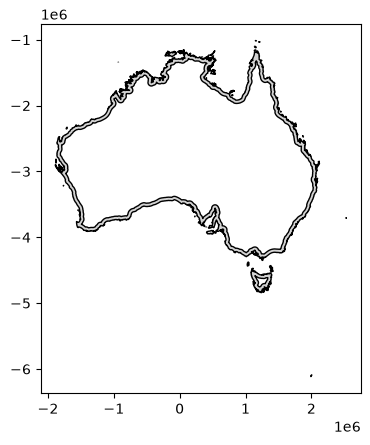

In [150]:
# Bulding the coastal shape

# Joins the states together and reprojects so distances are in m instead of degrees
aus = world_states[world_states["iso_a2"] == "AU"].to_crs("EPSG:3577")
aus_shape = aus.union_all()

# Shriks the shape inwards by 50km, inside of which is the deep interior 
# i.e. coastal areas are in that first 50km fom the coast
interior = aus_shape.buffer(-50_000)

gpd.GeoSeries([aus_shape, interior]).plot(color=["lightgrey", "white"], edgecolor="black")

In [151]:
# Check coordinate reference system
print(qld.crs)

EPSG:4326


In [152]:
# 1. label your points as lat/long (this doesn't change any coordinates)
gdf = gdf.set_crs("EPSG:4326")
print(gdf.crs)

# 2. make a metre-based copy of Queensland
qld_m = qld.to_crs("EPSG:3577")
print(qld_m.crs)

EPSG:4326
EPSG:3577


<Axes: title={'center': 'QLD Coastal Zone'}>

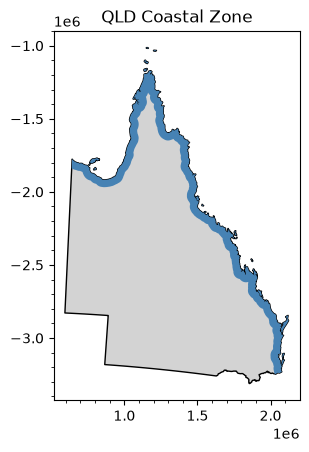

In [153]:
# Build the coastal zone for QLD only 

# removes deep interior, leaving coastal band
coastal_strip = aus_shape.difference(interior)
# only keeps the part of the band that's inside QLD
qld_coastal = qld_m.union_all().intersection(coastal_strip)

ax = qld_m.plot(color="lightgrey", edgecolor="black")

ax.set_title("QLD Coastal Zone")
ax.minorticks_on()
ax.set_axisbelow(True)

gpd.GeoSeries([qld_coastal], crs="EPSG:3577").plot(ax=ax, color="steelblue")

In [154]:
# Check coastal area is smaller than QLD area
print(qld_coastal.area / 1e6)          # km²
print(qld_m.union_all().area / 1e6)    # km²
print(qld_coastal.area/qld_m.union_all().area*100) # %

199858.19644621795
1730148.5959606958
11.551504703862916


## Sampling points inside the coastal zone

In [155]:
np.random.seed(42)

minx, miny, maxx, maxy = qld_coastal.bounds   # bounding box, in metres

n_candidates = 2000

x = np.random.uniform(minx, maxx, size=n_candidates)
y = np.random.uniform(miny, maxy, size=n_candidates)

candidates = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs="EPSG:3577")

# 1. add an in_coastal column using .within() against qld_coastal
# 2. keep only the True rows and take the first 10
# 3. convert to lat/long with .to_crs("EPSG:4326")



In [156]:

# add column to show which candidate points are in the coastal region
candidates["in_qld_coast"] = candidates.within(qld_coastal)

# filter for poins that fall in the coastal region
qld_coast_candidates = candidates[candidates["in_qld_coast"]]

# reset row index
qld_coast_candidates_clean = candidates[candidates["in_qld_coast"]].reset_index(drop=True)

# Take top 10 rows
ten_qld_coast = qld_coast_candidates_clean.head(10)

# convert lat and long to new crs
coastal_points = ten_qld_coast.to_crs("EPSG:4326")

coastal_points

,geometry,in_qld_coast
0,POINT (145.03119 -15.0185),True
1,POINT (145.75704 -18.29233),True
2,POINT (152.47841 -25.09739),True
3,POINT (146.00706 -18.67623),True
4,POINT (144.89958 -15.27601),True
5,POINT (152.26914 -24.75474),True
6,POINT (144.71581 -15.00074),True
7,POINT (149.3053 -21.8457),True
8,POINT (141.54095 -16.43731),True
9,POINT (142.1786 -12.78253),True


<Axes: >

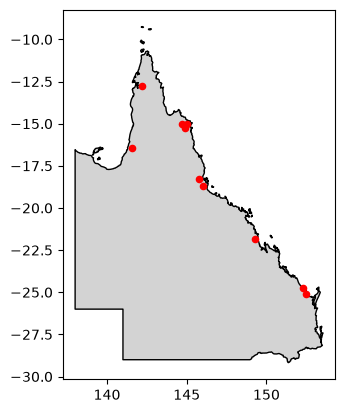

In [157]:
# Visually check location of points
ax = qld.plot(color="lightgrey", edgecolor="black")
coastal_points.plot(ax=ax, color="red", markersize=20)

In [158]:
# Checking how many candidates were valid (%)
print(candidates["in_qld_coast"].mean())

0.057


In [159]:
# check the estimate with a quick area calculation - it should be close to .mean(). 
# If the two numbers are far apart, something is wrong with the sampling or the CRS.
minx, miny, maxx, maxy = qld_coastal.bounds
box_area = (maxx - minx) * (maxy - miny)
print(qld_coastal.area / box_area)

0.060311517787657684


## Building the Exposure Table

In [160]:
# 1. make sure you're working in lat/long and have exactly 10 rows
coastal_points = coastal_points.to_crs("EPSG:4326").head(10).reset_index(drop=True)

# 2. build the table from the geometry
materials = ["timber", "brick_veneer", "concrete_block"]

df_coastal = pd.DataFrame({
    "policy_id": np.array([1,2,3,4,5,6,7,8,9,10]),                    
    "latitude": coastal_points.geometry.y,
    "longitude": coastal_points.geometry.x,
    "construction_type": np.random.choice(materials, size=10),           
    "sum_insured": np.random.uniform(2e5, 8e5, size=10).round(2), 
})

# 3. save without the index column
df_coastal.to_csv("qld_exposure_coast.csv", index=False)  

df_coastal 

,policy_id,latitude,longitude,construction_type,sum_insured
0,1,-15.018502,145.031188,brick_veneer,445073.35
1,2,-18.292329,145.757040,timber,607818.33
2,3,-25.097391,152.478414,timber,234008.26
3,4,-18.676231,146.007062,concrete_block,220803.62
4,5,-15.276010,144.899578,concrete_block,435146.34
5,6,-24.754739,152.269141,timber,618298.22
6,7,-15.000745,144.715814,timber,316061.21
7,8,-21.845701,149.305298,brick_veneer,584902.69
8,9,-16.437310,141.540951,concrete_block,355896.88
9,10,-12.782526,142.178599,brick_veneer,731651.67


In [161]:
gdf_coastal = gpd.GeoDataFrame(
    df_coastal,
    geometry=gpd.points_from_xy(df_coastal["longitude"], df_coastal["latitude"]),
    crs="EPSG:4326",
)

In [162]:
print(gdf_coastal.within(qld.union_all()).value_counts())
print(gdf_coastal.to_crs("EPSG:3577").within(qld_coastal).value_counts())

True    10
Name: count, dtype: int64
True    10
Name: count, dtype: int64


## Complete Map
- Queensland boundary
- coastal zone
- colour-coded properties
- legend
- layer toggle

In [163]:
import os
import folium

colour_map = {
    "timber": "#d73027",
    "brick_veneer": "#fc8d59",
    "concrete_block": "#4575b4",
}

# lighter copies of the boundaries, for display only
qld_simple = qld.copy()
qld_simple["geometry"] = qld_simple.geometry.simplify(0.01)

coastal_ll = (
    gpd.GeoSeries([qld_coastal], crs="EPSG:3577")
    .to_crs("EPSG:4326")
    .simplify(0.01)
)

# base map, zoomed to the points
final_map = folium.Map(location=[-20, 147], zoom_start=5)
minx, miny, maxx, maxy = gdf_coastal.total_bounds
final_map.fit_bounds([[miny, minx], [maxy, maxx]])

# boundary layers
folium.GeoJson(
    qld_simple,
    name="Queensland",
    style_function=lambda f: {"color": "black", "weight": 1, "fillOpacity": 0.05},
).add_to(final_map)

folium.GeoJson(
    coastal_ll,
    name="50 km coastal zone",
    style_function=lambda f: {"color": "#4575b4", "weight": 0.5, "fillColor": "#4575b4", "fillOpacity": 0.25},
).add_to(final_map)

# property markers
properties = folium.FeatureGroup(name="Properties")
for _, row in gdf_coastal.iterrows():
    popup_text = (
        f"<b>Policy {row['policy_id']}</b><br>"
        f"Construction: {row['construction_type']}<br>"
        f"Sum insured: ${row['sum_insured']:,.0f}<br>"
        f"Lat/Long: {row['latitude']:.2f}, {row['longitude']:.2f}"
    )
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=7,
        color=colour_map[row["construction_type"]],
        fill=True,
        fill_opacity=0.85,
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"Policy {row['policy_id']}",
    ).add_to(properties)
properties.add_to(final_map)

# layer toggle
folium.LayerControl().add_to(final_map)

# legend (folium has no built-in one)
items = "".join(
    f'<span style="color:{c};font-size:16px;">&#9679;</span> {k}<br>'
    for k, c in colour_map.items()
)
legend_html = (
    '<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; '
    'background: white; padding: 10px 12px; border: 1px solid grey; '
    'border-radius: 6px; font-size: 13px;">'
    f"<b>Construction type</b><br>{items}</div>"
)
final_map.get_root().html.add_child(folium.Element(legend_html))

os.makedirs("outputs", exist_ok=True)
final_map.save("outputs/qld_coastal_exposure_map.html")
final_map